In [360]:
#그래프관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures    # 다항특성 자동생성
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error         # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler        # 정규화 클래스


In [342]:
df = pd.read_csv('data/MultipleLinearRegressionData.csv')
df.head()

,hour,absent,place,score
0,0.5,3,Home,10
1,1.2,4,Library,8
2,1.8,2,Cafe,14
3,2.4,0,Cafe,26
4,2.6,2,Home,22


In [343]:
df['place'].unique()

<StringArray>
['Home', 'Library', 'Cafe']
Length: 3, dtype: str

In [ ]:
data = df.iloc[:,:-2].values
label = df.iloc[:,-1].values


<StringArray>
[   'Home', 'Library',    'Cafe',    'Cafe',    'Home',    'Home', 'Library',
 'Library',    'Home',    'Cafe',    'Cafe',    'Cafe', 'Library',    'Cafe',
 'Library',    'Home',    'Cafe',    'Home', 'Library', 'Library']
Length: 20, dtype: str

In [ ]:
#원핫인코딩 작업 - 다중공선성 : 특정컬림이 다른 컬럼에 많은 영향을 미칠때 처리방법
place = df['place'].to_numpy().reshape(-1,1) #2차원배열로 가져옴
encoder = OneHotEncoder(sparse_output=False,drop='first')
result = encoder.fit_transform(place)


In [346]:
# data + result 합치기

total_data = np.concatenate((data,result),axis=1)

In [347]:
# 데이터 변환 - float

In [348]:
train_data,test_data,train_label,test_label = train_test_split(total_data,label,random_state=42)
train_data

array([[ 3.2,  0. ,  1. ,  0. ],
       [ 5.8,  0. ,  0. ,  0. ],
       [ 2.4,  0. ,  0. ,  0. ],
       [ 8.6,  1. ,  0. ,  1. ],
       [ 7.2,  2. ,  0. ,  0. ],
       [ 6.1,  1. ,  0. ,  0. ],
       [ 1.8,  2. ,  0. ,  0. ],
       [ 5. ,  1. ,  0. ,  0. ],
       [10. ,  0. ,  0. ,  1. ],
       [ 2.6,  2. ,  1. ,  0. ],
       [ 6. ,  3. ,  0. ,  1. ],
       [ 4.4,  0. ,  0. ,  1. ],
       [ 5.3,  2. ,  0. ,  0. ],
       [ 6.2,  1. ,  0. ,  1. ],
       [ 3.9,  0. ,  0. ,  1. ]])

In [349]:
poly = PolynomialFeatures(degree=1 ,include_bias=False)
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)
train_poly.shape

(15, 4)

In [350]:
print(poly.get_feature_names_out())

['x0' 'x1' 'x2' 'x3']


In [351]:
ss = StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)

In [352]:
alpha_list = [0.001,0.01,0.1,0,1,10,100]
train_score = []
test_score = []

for alpha in alpha_list :
    ridge = Ridge(alpha=alpha)
    ridge.fit(train_scaled,train_label)
    score = ridge.score(train_scaled,train_label)
    score2 = ridge.score(test_scaled,test_label)
    train_score.append(score)
    test_score.append(score2)


In [353]:
train_score
test_score
no_list = np.arange(1,8)
no_list

array([1, 2, 3, 4, 5, 6, 7])

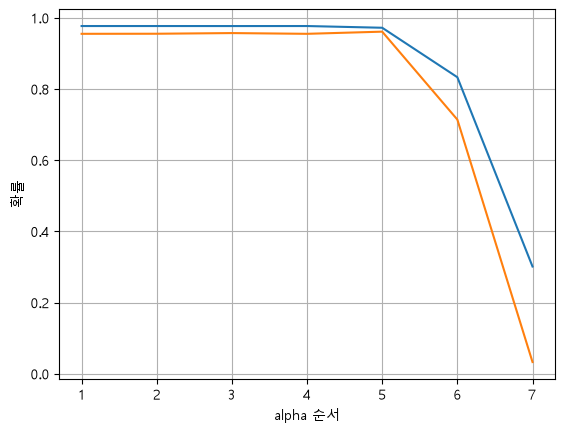

In [354]:
plt.plot(no_list,train_score)
plt.plot(no_list,test_score)
plt.xlabel('alpha 순서')
plt.ylabel('확률')
plt.grid()
plt.show()

In [355]:
print(score)
print(score2)

0.30138985257673023
0.033057880594906885


In [356]:
lr = LinearRegression()
lr.fit(train_poly,train_label)
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print(score)
print(score2)

0.9770255436151456
0.9551480880200325


In [ ]:
input1 = [[4.2,1,'Cafe']]
place = encoder.transform([[input1[0][2]]])
data = np.array([[input1[0][0],input1[0][1]]])
total_input = np.concatenate((data,place),axis=1)
input_poly=poly.transform(total_input)
input_scaled = ss.transform(input_poly)

predict = ridge.predict(input_scaled)
print(predict)

input2 = input('공부시간,결석횟수,장소 를 입력하세요. : ').split(',')

data = np.array([input2])


[47.53860583]


In [392]:
# Home 1., 0.
# Library 0., 1.
# Cafe 0., 0.


in_data = input('공부시간,결석횟수,장소를 입력하세요. 예)4.2,1,cafe ')
in_data = in_data.split(',')
out_data = []
out_data.append(float(in_data[0]))
out_data.append(float(in_data[1]))
if in_data[2] == 'Home':
    out_data.append(1.0)
    out_data.append(0.0)
elif in_data[2] =='Library':
    out_data.append(0.0)
    out_data.append(1.0)
elif in_data[2] =='Cafe':
    out_data.append(0.0)
    out_data.append(0.0)

predict = lr.predict([out_data])
print(f'예측점수 : {predict[0]:.2f}점')
print(out_data)
# print(in_data)
# print(out_data)

예측점수 : 44.09점
[4.2, 1.0, 0.0, 1.0]


In [393]:
result

array([[1., 0.],
       [0., 1.],
       [0., 0.],
       [0., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 1.],
       [0., 0.],
       [0., 1.],
       [1., 0.],
       [0., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.]])

In [ ]:
predict = lr.predict([out_data])
print('예측점수 : ',predict)

1.5

In [ ]:
ridge = Ridge(1)
ridge.fit(train_scaled,train_label)
score = ridge.score(train_scaled,train_label)
score2 = ridge.score(test_scaled,test_label)
print(score)
print(score2)

0.9721988323063082
0.9612273725160108
